# ผลประเมินโมเดล Aphrodize เทียบกับ U-Net ของผู้วิจัย

เปรียบเทียบ **U-Net ที่ทีม Aphrodize fine-tune ในการทดลองนี้** กับ **official Stage-2 pretrained U-Net** ของ FFHQ-Wrinkle โดยใช้ภาพทดสอบ, manual masks, preprocessing, resolution และ threshold เดียวกัน ผลทั้งหมดอ่านจาก inference ที่รันจริงในการทดลองนี้

เป็น **pilot experiment** เพื่อแสดงกระบวนการฝึกและประเมิน ไม่ใช่ผลฝึกเต็มชุดหรือหลักฐานความแม่นยำกับผู้ใช้จริง โมเดลของเราเริ่มจาก pretrained ของผู้วิจัยและปรับน้ำหนักต่อ ไม่ได้ฝึกจากศูนย์

**Run All** อ่านผลที่บันทึกไว้และสร้างกราฟเท่านั้น ไม่ฝึกใหม่ ไม่เลือก threshold จาก test set และไม่เปิดใช้ checkpoint ในแอป

## 1. แหล่งข้อมูลและวิธีทำซ้ำ

- Dataset: FFHQ-Wrinkle manual wrinkle masks และ face-parsing labels ของผู้วิจัย; ภาพ RGB จาก FFHQ mirror ที่ตรึง revision และตรวจ SHA-256
- Test: official test IDs ทั้ง 100 ภาพ; train 50 และ validation 20 ภาพสุ่มด้วย seed 2024 จาก ID ที่เหลือ ทั้งสาม split ไม่มี image ID ซ้ำ
- Input: masked RGB + texture ที่สร้างด้วยโค้ด Aphrodize บนภาพต้นทาง จากนั้น resize เป็น 512×512; mask ใช้ nearest-neighbor
- Fine-tune ทุกพารามิเตอร์ 3 epochs, Adam lr=1e-4, batch size 1, cross-entropy เดิมของระบบ เลือก epoch ด้วย validation micro Dice เท่านั้น
- ทั้งสองโมเดลใช้ softmax(class=1) ≥ 0.5 AND face mask (skin/nose labels 1 และ 10)

รันใหม่จาก repository root ด้วย environment เดิม และเลือก output ใหม่เพื่อรักษาผลเดิม:

```powershell
ai/.venv/Scripts/python.exe ai/scripts/compare_wrinkle_finetuning.py --output storage/artifacts/ffhq_wrinkle_comparison_new
```

Notebook ต้องมี `numpy`, `matplotlib`, `Pillow`, `IPython` ส่วนสคริปต์ฝึกใช้ environment ใน `ai/.venv` ที่มี PyTorch

อ้างอิง: [FFHQ-Wrinkle](https://github.com/labhai/ffhq-wrinkle-dataset), [Paper](https://arxiv.org/abs/2408.10060), [provenance/licence ของโปรเจกต์](../../../ai/ffhq_wrinkle/THIRD_PARTY.md) ข้อมูลสำหรับงานวิจัยภายใต้เงื่อนไขใบอนุญาตที่ระบุในแหล่งต้นทาง

In [1]:
from pathlib import Path
import csv
import json
import sys
import hashlib

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "ai/scripts/compare_wrinkle_finetuning.py").is_file())
sys.path.insert(0, str(ROOT))
from ai.ffhq_wrinkle.metrics import summarize_rows
REPORT_DIR = ROOT / "storage/artifacts/ffhq_wrinkle_comparison_20261008"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

def show_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

report = json.loads((REPORT_DIR / "metrics.json").read_text(encoding="utf-8"))
protocol = report["protocol"]
models = report["models"]
names = [m["name"] for m in models]
summary = {m["name"]: m["overall"]["micro"] for m in models}
with (REPORT_DIR / report["artifacts"]["per_image_csv"]).open(encoding="utf-8", newline="") as f:
    rows = list(csv.DictReader(f))
print("Actual experiment:", report["created_at_utc"])
print("Selected epoch (validation only):", report["selected_epoch"])
print("Report SHA-256:", hashlib.sha256((REPORT_DIR / "metrics.json").read_bytes()).hexdigest())


Actual experiment: 2026-10-08T06:55:23.282453+00:00
Selected epoch (validation only): 3
Report SHA-256: b4b2bf87a908c3d8fc36e18dbc1d595f1638c079a523dfeff0a2c4bbaa9f2742


## 2. ตรวจความถูกต้องก่อนแสดงผล

ตรวจ split ไม่ซ้ำ, test IDs เหมือนกัน, จำนวนพิกเซลรวมตรงกับ 100 ภาพ และรวมผลรายภาพจาก CSV ซ้ำเพื่อตรวจ JSON ตรวจด้วยว่า checkpoint หลังฝึกเปลี่ยนจากของผู้วิจัยจริง

In [2]:
assert protocol["experiment_version"] == "aphrodize-unet-pilot-v1"
splits = protocol["splits"]
assert not (set(splits["train"]) & set(splits["validation"]))
assert not ((set(splits["train"]) | set(splits["validation"])) & set(splits["test"]))
assert len(splits["test"]) == 100
assert len(models) == 2 and models[0]["checkpoint_sha256"] != models[1]["checkpoint_sha256"]
for model in models:
    selected = [r for r in rows if r["model"] == model["name"]]
    ids = [r["image_id"] for r in selected]
    assert len(ids) == len(set(ids)) == 100
    assert set(ids) == set(splits["test"])
    recomputed = summarize_rows(selected)
    for mode in ("micro", "macro"):
        for key in model["overall"][mode]:
            assert np.isclose(recomputed[mode][key], model["overall"][mode][key]), (mode, key)
    assert recomputed["micro"]["pixel_count"] == 100 * np.prod(protocol["resolution"])
print("PASS: disjoint splits, matching test IDs, exact pixel totals, CSV/JSON consistency and distinct checkpoints")
print(json.dumps({k: protocol[k] for k in ("resolution", "epochs", "learning_rate", "loss", "threshold", "preprocessing", "selection")}, indent=2))
for model in models:
    print(model["name"], "checkpoint SHA-256:", model["checkpoint_sha256"])


PASS: disjoint splits, matching test IDs, exact pixel totals, CSV/JSON consistency and distinct checkpoints
{
  "resolution": [
    512,
    512
  ],
  "epochs": 3,
  "learning_rate": 0.0001,
  "loss": "unweighted_cross_entropy",
  "threshold": 0.5,
  "preprocessing": "aligned-FFHQ+ffhq-wrinkle-texture-v1-bt709-dark-floor+area-resize-512",
  "selection": "maximum validation micro Dice; test evaluated only after selection"
}
Official U-Net checkpoint SHA-256: 883034b3e0726dcdae946c312106dfde1d354ea5455fa21cba045a73058f4a25
Aphrodize U-Net checkpoint SHA-256: 80a59160b651d14177389ff6a1dc9c95575468b43c640fbec404cd559d5e2718


## 3. คะแนนรวมบน test set เดียวกัน

**Micro Dice/F1** และ **IoU** วัดความซ้อนทับของพิกเซลริ้วรอยกับ manual mask; **precision** วัดสัดส่วนพิกเซลทำนายริ้วรอยที่ถูก; **recall** วัดสัดส่วนริ้วรอยจริงที่ตรวจพบ

Micro รวม TP/FP/FN/TN ของทั้งชุดก่อนคำนวณ; macro Dice เป็นค่าเฉลี่ย Dice รายภาพ ไม่ใช้ pixel accuracy เป็นข้อสรุปหลักเพราะ background มีจำนวนมากกว่า

| Model | Micro Dice | Micro IoU | Precision | Recall | Macro Dice |
|---|---:|---:|---:|---:|---:|
| Official U-Net | 0.568695 | 0.397326 | 0.549719 | 0.589028 | 0.541385 |
| Aphrodize U-Net | 0.434194 | 0.277298 | 0.649223 | 0.326165 | 0.408440 |


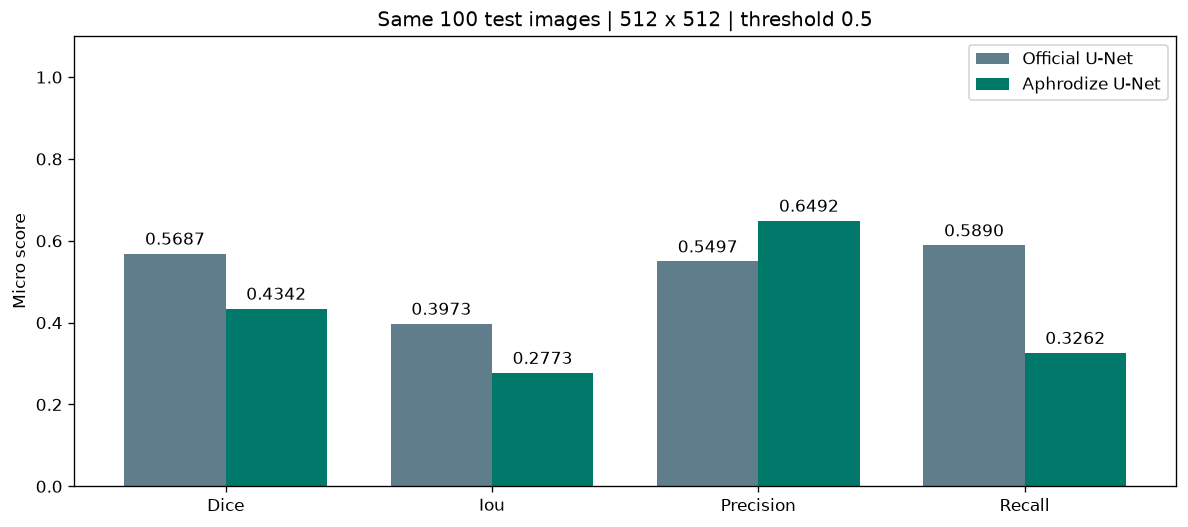

**Aphrodize − official baseline:** Dice -0.134500; Iou -0.120028; Precision +0.099504; Recall -0.262862

In [3]:
keys = ["dice", "iou", "precision", "recall"]
table = "| Model | Micro Dice | Micro IoU | Precision | Recall | Macro Dice |\n|---|---:|---:|---:|---:|---:|\n"
for model in models:
    micro = model["overall"]["micro"]
    values = [micro[k] for k in keys] + [model["overall"]["macro"]["dice"]]
    table += "| " + model["name"] + " | " + " | ".join(f"{v:.6f}" for v in values) + " |\n"
display(Markdown(table))
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(keys))
for offset, model, color in zip((-0.19, 0.19), models, ("#607D8B", "#00796B")):
    bars = ax.bar(x + offset, [model["overall"]["micro"][k] for k in keys], 0.38,
                  label=model["name"], color=color)
    ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set(xticks=x, xticklabels=[k.title() for k in keys], ylim=(0, 1.1),
       ylabel="Micro score", title="Same 100 test images | 512 x 512 | threshold 0.5")
ax.legend()
show_plot(fig, "model_comparison.png")
base, ours = [m["overall"]["micro"] for m in models]
display(Markdown("**Aphrodize − official baseline:** " + "; ".join(f"{k.title()} {ours[k] - base[k]:+.6f}" for k in keys)))


## 4. Confusion matrix จากผลทำนายจริง

แถว = ground truth, คอลัมน์ = prediction; ตัวเลขคือจำนวนพิกเซลรวมจาก 100 ภาพ สีและเปอร์เซ็นต์ normalize ภายในแต่ละแถวเพื่ออ่านข้อผิดพลาดของริ้วรอยได้แม้ background มากกว่า

TN = background ที่ถูก, FP = ทำนายริ้วรอยเกิน, FN = ริ้วรอยที่พลาด, TP = ริ้วรอยที่ถูก

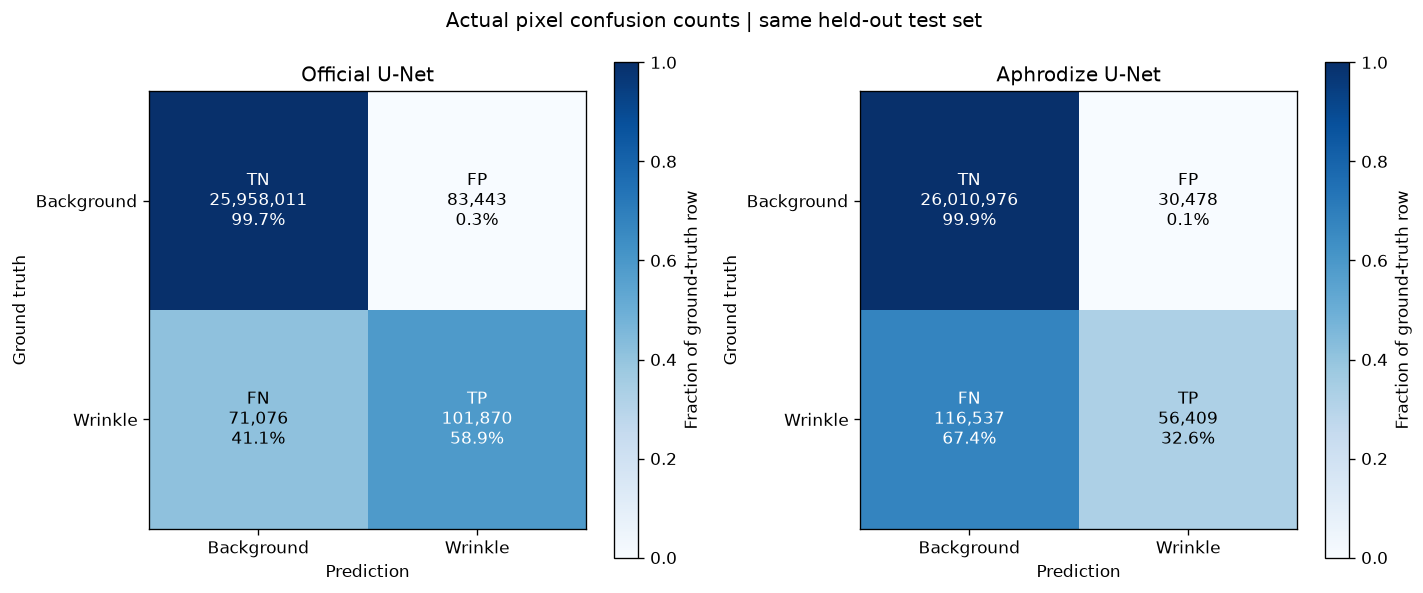

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = [["TN", "FP"], ["FN", "TP"]]
for ax, model in zip(axes, models):
    m = model["overall"]["micro"]
    counts = np.array([[m["true_negative"], m["false_positive"]],
                       [m["false_negative"], m["true_positive"]]], dtype=np.int64)
    totals = counts.sum(axis=1, keepdims=True)
    rates = np.divide(counts, totals, out=np.zeros_like(counts, dtype=float), where=totals != 0)
    im = ax.imshow(rates, vmin=0, vmax=1, cmap="Blues")
    for (i, j), count in np.ndenumerate(counts):
        ax.text(j, i, f"{labels[i][j]}\n{count:,}\n{rates[i,j]:.1%}", ha="center", va="center",
                color="white" if rates[i,j] > 0.5 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Background", "Wrinkle"],
           yticklabels=["Background", "Wrinkle"], xlabel="Prediction", ylabel="Ground truth", title=model["name"])
    fig.colorbar(im, ax=ax, label="Fraction of ground-truth row")
fig.suptitle("Actual pixel confusion counts | same held-out test set")
show_plot(fig, "pixel_confusion_matrix.png")


## 5. ประวัติการฝึกและการเลือก epoch

Training loss มาจากการฝึกจริง; validation Dice ใช้เลือก checkpoint ก่อนเปิดผล test เส้นประแสดง baseline ก่อน fine-tune ค่า train loss กับ validation Dice เป็นคนละตัวชี้วัด จึงไม่ใช้ความต่างของทั้งสองเส้นเพื่อสรุป overfitting โดยตรง

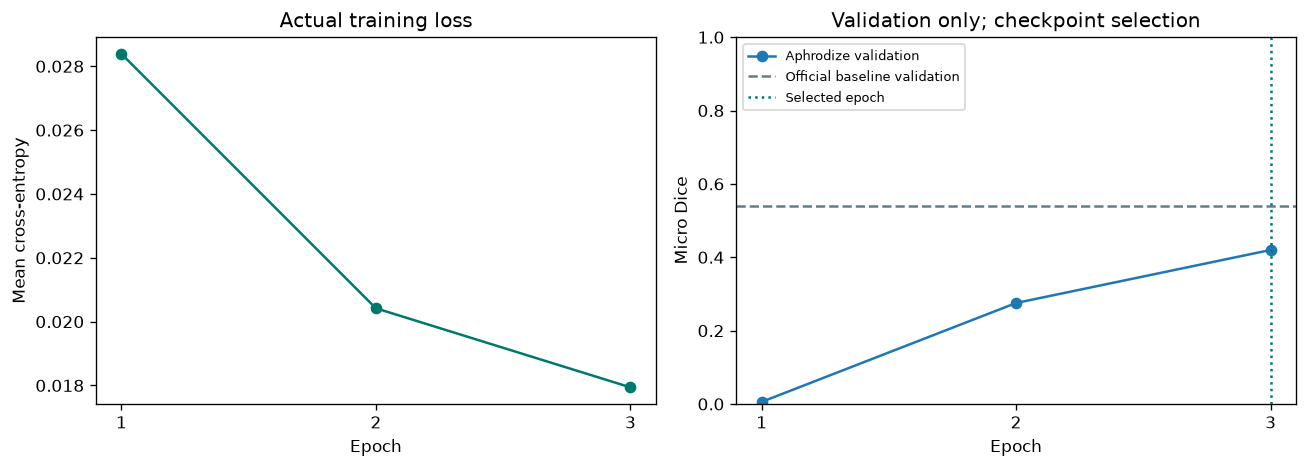

In [5]:
history = report["history"]
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, [h["train_loss"] for h in history], "o-", color="#00796B")
axes[0].set(xlabel="Epoch", ylabel="Mean cross-entropy", title="Actual training loss", xticks=epochs)
axes[1].plot(epochs, [h["validation"]["micro"]["dice"] for h in history], "o-", label="Aphrodize validation")
axes[1].axhline(report["baseline_validation"]["micro"]["dice"], ls="--", color="#607D8B", label="Official baseline validation")
axes[1].axvline(report["selected_epoch"], ls=":", color="#00796B", label="Selected epoch")
axes[1].set(xlabel="Epoch", ylabel="Micro Dice", title="Validation only; checkpoint selection", xticks=epochs, ylim=(0, 1))
axes[1].legend(fontsize=8)
show_plot(fig, "training_history.png")


## 6. ผลรายภาพแบบจับคู่

แต่ละจุดคือ test image เดียวกันบนทั้งสองโมเดล จุดเหนือเส้นทแยงหมายถึงโมเดล Aphrodize ได้ Dice สูงกว่า ช่วยให้เห็นว่าผลรวมเปลี่ยนเพราะหลายภาพดีขึ้นหรือบางภาพเพียงไม่กี่ภาพ

Aphrodize: improved 12 tied 0 decreased 88 of 100 images


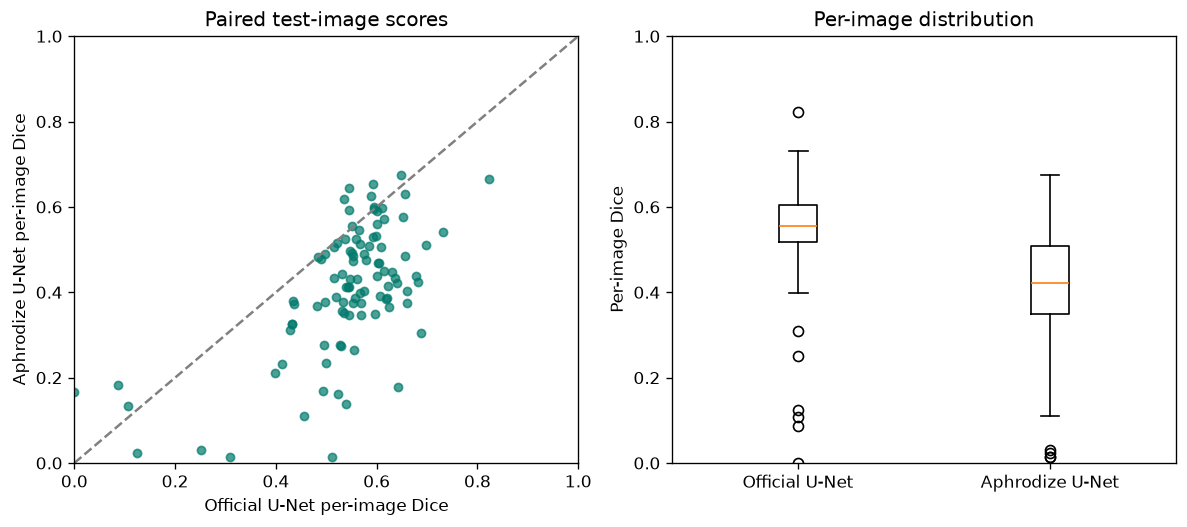

In [6]:
by_name = {name: {r["image_id"]: float(r["dice"]) for r in rows if r["model"] == name} for name in names}
a = np.array([by_name[names[0]][i] for i in splits["test"]])
b = np.array([by_name[names[1]][i] for i in splits["test"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(a, b, s=24, alpha=0.7, color="#00796B")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="Official U-Net per-image Dice", ylabel="Aphrodize U-Net per-image Dice", xlim=(0, 1), ylim=(0, 1), title="Paired test-image scores")
axes[1].boxplot([a, b], tick_labels=names)
axes[1].set(ylabel="Per-image Dice", ylim=(0, 1), title="Per-image distribution")
show_plot(fig, "paired_test_scores.png")
ties = np.isclose(a, b, rtol=0, atol=1e-12)
print("Aphrodize: improved", int(((b > a) & ~ties).sum()), "tied", int(ties.sum()), "decreased", int(((b < a) & ~ties).sum()), "of 100 images")


## 7. ตัวอย่าง prediction บนภาพเดียวกัน

ใช้ **3 IDs แรกตามลำดับ official test list ที่กำหนดไว้** เพื่อไม่เลือกเฉพาะตัวอย่างที่โมเดลเราทำได้ดี ทุก mask ใช้พิกัด 512×512 เดียวกัน

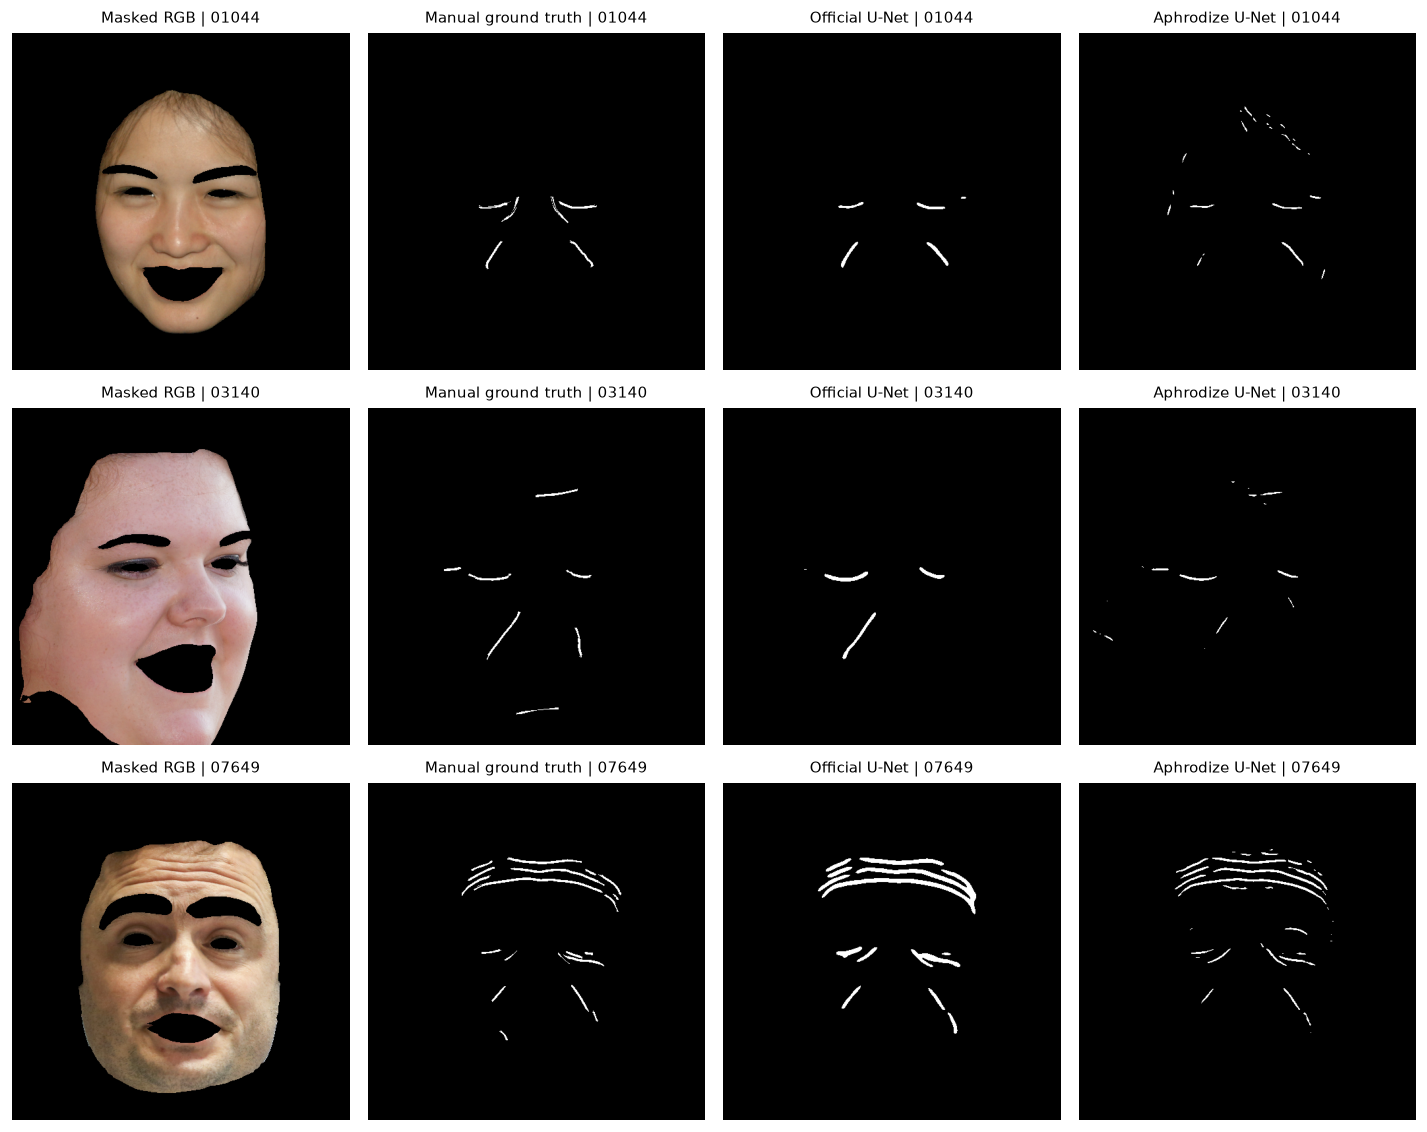

In [7]:
example_ids = splits["test"][:3]
fig, axes = plt.subplots(len(example_ids), 4, figsize=(12, 3.2 * len(example_ids)))
for row_index, image_id in enumerate(example_ids):
    with np.load(REPORT_DIR / "prepared" / f"{image_id}.npz", allow_pickle=False) as sample:
        image = np.rint((sample["x"][:3].transpose(1, 2, 0) + 1) * 127.5).astype(np.uint8)
        images = [image, sample["target"]]
    for name in names:
        path = REPORT_DIR / "predictions" / name.lower().replace(" ", "_") / f"{image_id}.png"
        with Image.open(path) as opened:
            images.append(np.asarray(opened.convert("L")))
    for ax, image, title in zip(axes[row_index], images, ["Masked RGB", "Manual ground truth", *names]):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255 if image.dtype == np.uint8 else 1)
        ax.set_title(f"{title} | {image_id}", fontsize=9)
        ax.axis("off")
show_plot(fig, "prediction_examples.png")


## 8. ข้อสรุปสำหรับการนำเสนอ

อ่านผลจากการทดลองจริงโดยไม่สมมติว่า fine-tune แล้วจะดีขึ้นเสมอ หากคะแนนลดลง ให้รายงานว่าการฝึกครั้งนี้ยังไม่ทำให้โมเดลดีขึ้น และใช้ validation/test เพื่ออธิบายสิ่งที่พบ

In [8]:
delta = summary[names[1]]["dice"] - summary[names[0]]["dice"]
verdict = "สูงกว่า" if delta > 0 else ("ต่ำกว่า" if delta < 0 else "เท่ากับ")
display(Markdown(f"โมเดล Aphrodize หลัง fine-tune มี **micro Dice {verdict} baseline {abs(delta):.6f}** บน test set เดียวกัน 100 ภาพ เลือก checkpoint จาก epoch {report['selected_epoch']} ด้วย validation เท่านั้น"))
display(Markdown("**ขอบเขต:** ฝึก 50 ภาพ, validation 20 ภาพ, test 100 ภาพ; 3 epochs; resolution 512×512; เป็น pilot experiment และไม่ได้ฝึกจากศูนย์"))
for limitation in protocol["limitations"]:
    print("-", limitation)
print("Saved figures:", FIGURE_DIR)

base, ours = [model["overall"]["micro"] for model in models]
display(Markdown(f"**ลักษณะข้อผิดพลาด:** precision {base['precision']:.4f} → {ours['precision']:.4f}; recall {base['recall']:.4f} → {ours['recall']:.4f}; FP {base['false_positive']:,} → {ours['false_positive']:,}; FN {base['false_negative']:,} → {ours['false_negative']:,}. ต้องดูทั้งการตรวจเกินและการพลาดริ้วรอย ไม่สรุปจาก precision เพียงค่าเดียว"))


- Small pilot subset; not full-data training
- Image-ID disjoint splits; identity overlap is unknown
- Generated texture and resized inputs differ from the published 1024px evaluation
- FFHQ research data; not evaluation on Aphrodize users
Saved figures: D:\CoE Y.4 T.1\241-353\code\Aphrodize\storage\artifacts\ffhq_wrinkle_comparison_20261008\figures


โมเดล Aphrodize หลัง fine-tune มี **micro Dice ต่ำกว่า baseline 0.134500** บน test set เดียวกัน 100 ภาพ เลือก checkpoint จาก epoch 3 ด้วย validation เท่านั้น

**ขอบเขต:** ฝึก 50 ภาพ, validation 20 ภาพ, test 100 ภาพ; 3 epochs; resolution 512×512; เป็น pilot experiment และไม่ได้ฝึกจากศูนย์

**ลักษณะข้อผิดพลาด:** precision 0.5497 → 0.6492; recall 0.5890 → 0.3262; FP 83,443 → 30,478; FN 71,076 → 116,537. ต้องดูทั้งการตรวจเกินและการพลาดริ้วรอย ไม่สรุปจาก precision เพียงค่าเดียว

### ข้อจำกัดที่ควรบอกอาจารย์

- ทั้งสองตัวใช้สถาปัตยกรรม U-Net เดียวกัน ต่างกันที่น้ำหนักก่อน/หลัง fine-tune จึงวัดผลของการฝึกต่อได้ตรงประเด็น
- จำนวนภาพฝึกน้อย และ mask ริ้วรอยเป็นคลาสส่วนน้อย cross-entropy อาจทำให้โมเดลทำนาย background มากขึ้น ต้องอ่าน precision/recall และ confusion matrix คู่กับ Dice
- แยกตาม image ID; ไม่มี identity metadata จึงไม่ยืนยันว่าเป็นการแยกตามบุคคล
- preprocessing สร้าง texture ใหม่และ resize เป็น 512×512 ต่างจากรายงานทางการเดิมที่ใช้ published weak texture และ 1024×1024 **ห้ามนำคะแนนจากสอง protocol มาเทียบตรง ๆ**
- เป็นข้อมูล FFHQ สำหรับงานวิจัย ไม่ใช่ภาพผู้ใช้ Aphrodize หรือการประเมินทางคลินิก และยังไม่ใช้ผลนี้อ้างว่าโมเดลพร้อม production
- ไม่มีการปรับ threshold หรือเลือก epoch จาก test set และยังไม่อ้างนัยสำคัญทางสถิติจากความต่างคะแนนเพียงครั้งเดียว

ไฟล์หลัก: `metrics.json`, `protocol.json`, `history.json`, `per_image_metrics.csv`, `download_manifest.json` และกราฟใน `figures/` ใต้ `REPORT_DIR`; checkpoint ของเราอยู่ใน `storage/models/ffhq-wrinkle/experiments/`